# M1

In [1]:
# 터미널 실행후 touch 이정환_ML미니과제1.ipynb, code 이정환_ML미니과제1

# uv add scikit-learn, pandas, numpy, matplotlib, seaborn, ipykernel

# matplotlib.pyplot : 그래프 생성하고 설정하는 라이브러리 모듈
import matplotlib.pyplot as plt

# 한글 폰트 설정
# Windows OS
plt.rcParams["font.family"] = "Malgun Gothic"
# 맥 OS : plt.rcParams["font.family"] = "AppleGothic"

In [ ]:
import seaborn as sns

df = sns.load_dataset("diamonds")
print(df.shape)
# 53940 행 10 열

df.head(5)

df.info

print(df.isnull().sum())
# 모든행이 0이다

df.describe()
print(df["price"].mean())
print(df["price"].quantile(0.5))

mean = df["price"].mean().round(-1)
half = df["price"].quantile(0.5)

if mean > half :
    print("평균값 > 중앙값")
elif mean == half :
    print("평균 값과 중앙값이 같다")
else : print("평균값 < 중앙값")

# price의 최소 최대 값의 차이가 제일 크다
# 가로 세로 높이가 0인것도 있는데 price가 0이 아니다

(53940, 10)
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64
3932.799721913237
2401.0
평균값 > 중앙값


# M2

In [3]:
print((df["x"] == 0).sum()) # 8
print((df["y"] == 0).sum()) # 7
print((df["z"] == 0).sum()) # 20


df[df["x"] == 0]
df[df["y"] == 0]
df[df["z"] == 0]

8
7
20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


In [4]:
special_0x = df["x"] == 0
special_0y = df["y"] == 0
special_0z = df["z"] == 0

special_y = df["y"] > 20
# 24067, 49189

special_z = df["z"] > 20
# 48410
# 왜 이상한지는 모르겠음

import numpy as np
import pandas as pd
import seaborn as sns

clean = np.ones(len(df), dtype=bool)

clean[special_0x] = False
clean[special_0y] = False
clean[special_0z] = False
clean[special_y] = False
clean[special_z] = False

print("제거전 행수", len(df), "제거후 행 수", clean.sum())
# 제거전 행수 53940 제거후 행 수 53917

제거전 행수 53940 제거후 행 수 53917


# M3

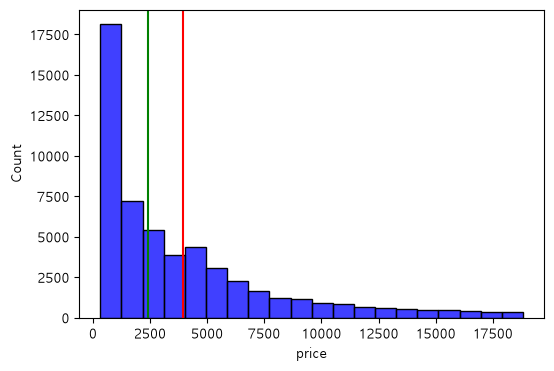

In [5]:

fig, ax = plt.subplots(figsize=(6,4)) 

sns.histplot(df["price"], bins=20, color="blue", edgecolor="black") 

ax.axvline(mean, color="red")

ax.axvline(half, color="green")


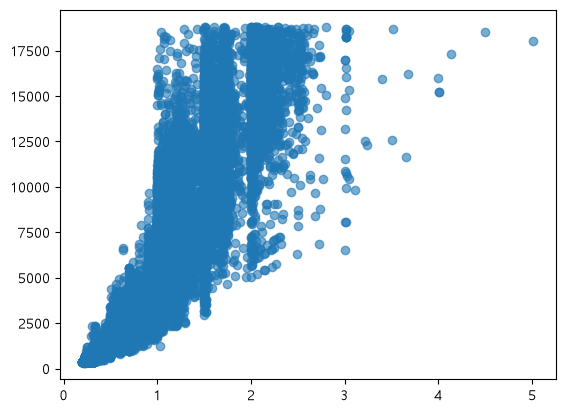

상관계수: 0.9215913011934768
상관계수: -0.010647404584142985
상관계수: 0.1271339021217421
상관계수: 0.8844351610161272
상관계수: 0.865420897864187
상관계수: 0.8612494438514486


In [6]:
plt.Figure(figsize=(8,5))

plt.scatter(df["carat"], df["price"], alpha=0.6)

# clean.sample(3000, random_state=42) 어디에 넣는지 모르겠음

plt.show()

df.select_dtypes("number")

print("상관계수:",df["price"].corr(df["carat"]))
print("상관계수:",df["price"].corr(df["depth"]))
print("상관계수:",df["price"].corr(df["table"]))
print("상관계수:",df["price"].corr(df["x"]))
print("상관계수:",df["price"].corr(df["y"]))
print("상관계수:",df["price"].corr(df["z"]))

# carat의 price 상관계수가 1에 가까워 가격예측 활용에 용이함

# M4

기울기 w: 7756.43, 절편 b: -2256.36
0.25 캐럿 예측값 : -320.0
0.5 캐럿 예측값 : 1620.0
1.0 캐럿 예측값 : 5500.0
0.5 캐럿 예측값 : 5500.0


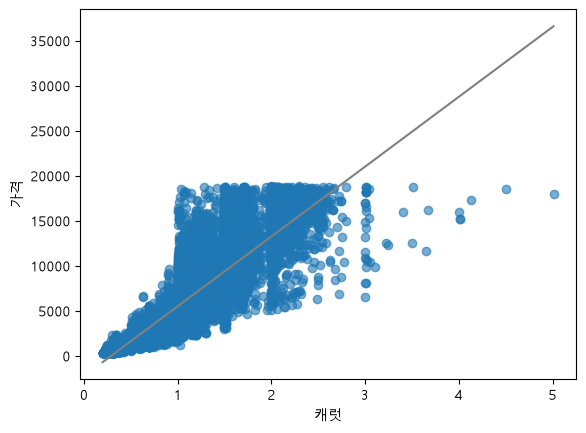

In [7]:
from sklearn.linear_model import LinearRegression

X_train = df[["carat"]]
y_train = df["price"]

model = LinearRegression()

model.fit(X_train[["carat"]], y_train)

print(f"기울기 w: {model.coef_[0]:.2f}, 절편 b: {model.intercept_:.2f}")
# 기울기 w: 7756.43, 절편 b: -2256.36


# y= wx + b 캐럿(w)과 가격(y)이 정비례한다


quarter_d = pd.DataFrame({"carat": [0.25]})
predicted_q = model.predict(quarter_d)


half_d = pd.DataFrame({"carat": [0.5]})
predicted_h = model.predict(half_d)

one_d = pd.DataFrame({"carat": [1.0]})
predicted_o = model.predict(one_d)

double_d = pd.DataFrame({"carat": [1.0]})
predicted_d = model.predict(double_d)





print("0.25 캐럿 예측값 :", predicted_q[0].round(-1))
print("0.5 캐럿 예측값 :", predicted_h[0].round(-1))  # 특정 면적의 가격 예측
print("1.0 캐럿 예측값 :", predicted_o[0].round(-1))  # 특정 면적의 가격 예측
print("0.5 캐럿 예측값 :", predicted_d[0].round(-1))  # 특정 면적의 가격 예측
# 0.25 캐럿 예측값 : -320.0
# 0.5 캐럿 예측값 : 1620.0
# 1.0 캐럿 예측값 : 5500.0
# 0.5 캐럿 예측값 : 5500.0

y_pred = model.predict(X_train)

line = X_train.sort_values("carat")

line_pred = model.predict(line)


plt.Figure(figsize=(8,5))
plt.scatter(df["carat"], df["price"], alpha=0.6)

plt.plot(line["carat"], line_pred, color="gray", label="모델의 직선",)
plt.xlabel("캐럿")
plt.ylabel("가격")
plt.show()

# 음수인 이유 설명을 봐도 잘 모르겠음

# M5

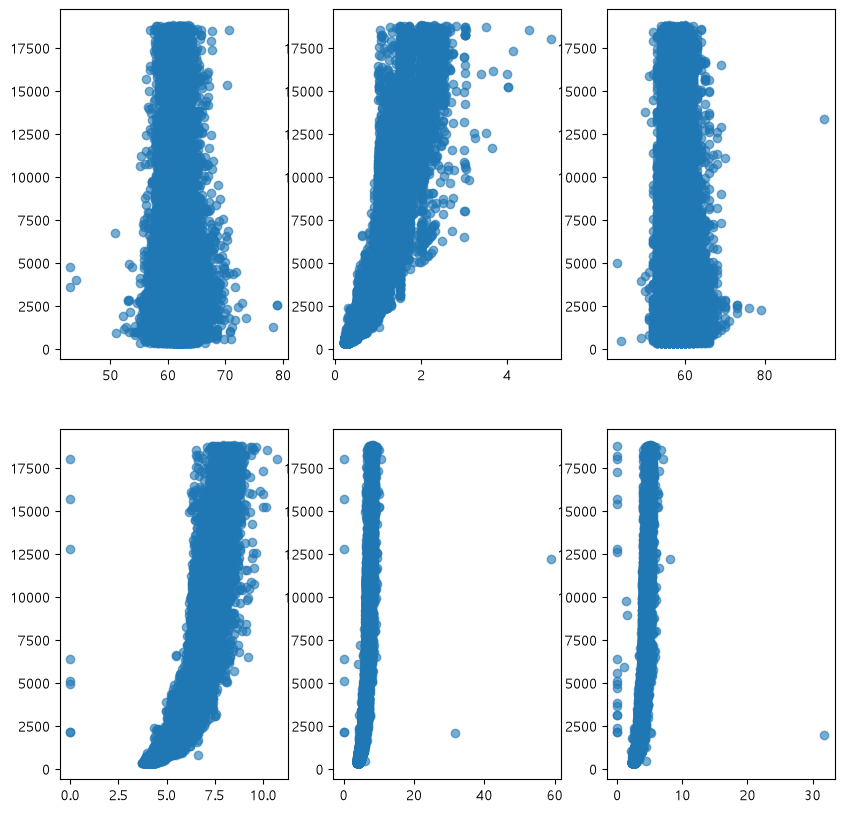

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

axes[0,0].scatter(df["depth"], df["price"], alpha=0.6)
axes[0,1].scatter(df["carat"], df["price"], alpha=0.6)
axes[0,2].scatter(df["table"], df["price"], alpha=0.6)
axes[1,0].scatter(df["x"], df["price"], alpha=0.6)
axes[1,1].scatter(df["y"], df["price"], alpha=0.6)
axes[1,2].scatter(df["z"], df["price"], alpha=0.6)


model.

# for로 하는건 아무리 봐도 모르겠음..